<a href="https://colab.research.google.com/github/saichandrakiranuppalapati45b4/Digital-Pilgrim/blob/main/EDA_INTERNAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Import Required Libraries and Load Dataset
Heading: Importing Libraries and Loading the Sales Dataset

Description: Import the Pandas and NumPy libraries for data manipulation and numerical operations. Load the sales transaction CSV file into a Pandas DataFrame for further analysis.


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/sales_transactions_regression.csv")

print(df)


    transaction_id region  product_id  product_id.1  sales_amount        date  \
0           T50000   West       426.0         426.0      965.0340  2024-01-01   
1           T50001   East       394.0         394.0      992.0770  2024-01-02   
2           T50002   West       446.0         446.0      323.4660  2024-01-03   
3           T50003  South       136.0         136.0     3439.5648  2024-01-04   
4           T50004  South       287.0         287.0     1207.0240  2024-01-05   
..             ...    ...         ...           ...           ...         ...   
255         T50027  North       141.0         141.0     1831.4256  2024-01-28   
256         T50000   West       426.0         426.0      965.0340  2024-01-01   
257         T50125  SOUTH       115.0         115.0      426.1950  2024-05-05   
258         T50190   East         NaN           NaN      965.5788  2024-07-09   
259         T50112    NaN         NaN           NaN      317.2700  2024-04-22   

     units_sold  unit_price

Step 2: Checking Dataset Information
Description: Use the df.info() function to display the structural information of the dataset, including the total number of entries, column names, non-null values, data types, and memory usage. This helps identify missing values and understand the dataset structure.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  249 non-null    object 
 1   region          245 non-null    object 
 2   product_id      239 non-null    float64
 3   product_id.1    239 non-null    float64
 4   sales_amount    249 non-null    float64
 5   date            248 non-null    object 
 6   units_sold      241 non-null    float64
 7   unit_price      239 non-null    float64
 8   discount_pct    244 non-null    float64
 9   store_id        249 non-null    object 
 10  product_id.2    239 non-null    float64
 11  product_id.3    239 non-null    float64
dtypes: float64(8), object(4)
memory usage: 24.5+ KB


Step 3: Checking Missing Values in the Dataset
Description: Use the df.isnull().sum() function to identify and count the missing (null) values in each column of the dataset. This helps assess data quality and determine which columns require data cleaning or missing-value treatment.


In [5]:
df.isnull().sum()

,0
transaction_id,11
region,15
product_id,21
product_id.1,21
sales_amount,11
date,12
units_sold,19
unit_price,21
discount_pct,16
store_id,11


Step 4: Identifying Duplicate Records in the Dataset
Description: Use the df.duplicated().sum() function to identify and count duplicate rows in the dataset. Duplicate records can affect the accuracy of statistical analysis and machine learning models. This step helps determine whether duplicate records need to be removed during data preprocessing.

In [7]:
print("duplicates:",df.duplicated().sum())

duplicates: 10


Step 5: Removing Duplicate Records and Unnecessary Columns
Description: In this step, identify and remove duplicate records from the dataset using drop_duplicates(). Then remove unnecessary duplicate product ID columns (product_id.1, product_id.2, and product_id.3) using drop() with errors='ignore'. This reduces redundancy and improves dataset quality.


In [11]:

print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

df = df.drop(columns=[
    "product_id.1 ",
    "product_id.2 ",
    "product_id.3 "
], errors='ignore')

print("Duplicates after:", df.duplicated().sum())

print("Updated dataset shape:", df)


Duplicates before: 0
Duplicates after: 0
Updated dataset shape:     transaction_id region  product_id  product_id.1  sales_amount        date  \
0           T50000   West       426.0         426.0      965.0340  2024-01-01   
1           T50001   East       394.0         394.0      992.0770  2024-01-02   
2           T50002   West       446.0         446.0      323.4660  2024-01-03   
3           T50003  South       136.0         136.0     3439.5648  2024-01-04   
4           T50004  South       287.0         287.0     1207.0240  2024-01-05   
..             ...    ...         ...           ...           ...         ...   
245         T50245   West       391.0         391.0     1687.2426  2024-09-02   
246         T50246   Nort       365.0         365.0      492.7580         NaN   
247         T50247    Wet       346.0         346.0     1131.5192  2024-09-04   
248         T50248  South         NaN           NaN      927.3030  2024-09-05   
249         T50249  North       234.0        

Step 6: Standardizing Inconsistent Region Names
Description: In this step, standardize inconsistent region names in the dataset using the replace() function. Correct spelling mistakes, abbreviations, and capitalization differences so that each region has a consistent name. This improves the accuracy of regional sales analysis.

In [12]:
region_mapping = {
    "EAST": "East",
    "Eat": "East",
    "Eas": "East",
    "ast": "East",
    "est": "East",
    "WEST": "West",
    "Wet": "West",
    "Wst": "West",
    "wes": "West",
    "NORTH": "North",
    "Nort": "North",
    "Norh": "North",
    "noth": "North",
    "SOUTH": "South",
    "Soth": "South"
}

df["region"] = df["region"].replace(region_mapping)

print("Updated Region Values:")
print(df["region"].value_counts(dropna=False))


Updated Region Values:
region
East     64
West     61
North    56
South    50
NaN      14
Wes       2
Noth      1
orth      1
Nrth      1
Name: count, dtype: int64


Step 7: Checking and Handling Missing Values
Description: In this step, identify missing values in each column using isnull().sum(). Then calculate the percentage of missing values to understand the extent of incomplete data. This helps decide the appropriate treatment for missing values without introducing incorrect assumptions.

In [13]:

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage.round(2))

print("\nRows with Missing Values:")
print(df[df.isnull().any(axis=1)])


Missing Values Before Cleaning:
transaction_id    10
region            14
product_id        19
product_id.1      19
sales_amount      11
date              12
units_sold        17
unit_price        21
discount_pct      15
store_id          10
product_id.2      19
product_id.3      19
dtype: int64

Missing Value Percentage:
transaction_id    4.0
region            5.6
product_id        7.6
product_id.1      7.6
sales_amount      4.4
date              4.8
units_sold        6.8
unit_price        8.4
discount_pct      6.0
store_id          4.0
product_id.2      7.6
product_id.3      7.6
dtype: float64

Rows with Missing Values:
    transaction_id region  product_id  product_id.1  sales_amount        date  \
2           T50002   West       446.0         446.0      323.4660  2024-01-03   
3           T50003  South       136.0         136.0     3439.5648  2024-01-04   
7           T50007  North       122.0         122.0      148.1084  2024-01-08   
10          T50010   West       293.0         

Step 8: Handling Missing Sales Amounts
Description: In this step, handle missing values in the sales_amount column by calculating them using the available units_sold, unit_price, and discount_pct columns. The sales amount is calculated by multiplying the quantity sold by the unit price after applying the discount. This helps recover missing sales values without using arbitrary replacements

In [14]:

calculated_sales = (
    df["units_sold"] *
    df["unit_price"] *
    (1 - df["discount_pct"])
)

df["sales_amount"] = df["sales_amount"].fillna(
    calculated_sales
)

print("Missing Sales Amounts After Cleaning:")
print(df["sales_amount"].isnull().sum())


Missing Sales Amounts After Cleaning:
4


Step 9: Handling Missing Numerical Values
Description: In this step, identify and handle missing values in numerical columns such as units_sold, unit_price, and discount_pct. Use the median value of each column to fill missing entries. Median imputation is preferred over mean imputation because it is less sensitive to extreme values and outliers.

In [15]:
numeric_columns = [
    "units_sold",
    "unit_price",
    "discount_pct"
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing Numerical Values After Cleaning:")
print(df[numeric_columns].isnull().sum())


Missing Numerical Values After Cleaning:
units_sold      0
unit_price      0
discount_pct    0
dtype: int64


Step 10: Handling Missing Categorical Values
Description: In this step, handle missing values in categorical columns such as region, store_id, and product_id. Replace missing values with the mode (most frequently occurring value) of each column. This helps maintain dataset completeness while using existing category information.

For transaction_id, avoid mode imputation because every transaction should have its own unique identifier. Missing transaction IDs should remain unresolved until verified from the original source.

In [16]:
categorical_columns = [
    "region",
    "store_id",
    "product_id"
]

for col in categorical_columns:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Categorical Values After Cleaning:")
print(df[categorical_columns].isnull().sum())

print("\nMissing Transaction IDs:")
print(df["transaction_id"].isnull().sum())


Missing Categorical Values After Cleaning:
region        0
store_id      0
product_id    0
dtype: int64

Missing Transaction IDs:
10


Step 11: Converting Data Types and Validating the Dataset
Description: In this step, convert the columns into their appropriate data types. Convert the date column into datetime format and numerical columns into numeric data types. This ensures that the dataset is properly structured for statistical analysis and machine learning.

In [17]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_columns = [
    "sales_amount",
    "units_sold",
    "unit_price",
    "discount_pct"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Updated Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()


Updated Data Types:
transaction_id            object
region                    object
product_id               float64
product_id.1             float64
sales_amount             float64
date              datetime64[ns]
units_sold               float64
unit_price               float64
discount_pct             float64
store_id                  object
product_id.2             float64
product_id.3             float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  240 non-null    object        
 1   region          250 non-null    object        
 2   product_id      250 non-null    float64       
 3   product_id.1    231 non-null    float64       
 4   sales_amount    246 non-null    float64       
 5   date            238 non-null    datetime64[ns]
 6   units_sold      250 non-nul

Step 12: Final Data Validation and Quality Check
Description: In this step, perform a final quality check on the cleaned dataset. Verify missing values, duplicate records, dataset dimensions, and statistical information. This ensures that the dataset is consistent and ready for further exploratory data analysis and machine learning.

In [18]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)

print("\nStatistical Summary:")
print(df.describe())

print("\nUnique Regions:")
print(df["region"].unique())

print("\nUnique Stores:")
print(df["store_id"].unique())


Missing Values:
transaction_id    10
region             0
product_id         0
product_id.1      19
sales_amount       4
date              12
units_sold         0
unit_price         0
discount_pct       0
store_id           0
product_id.2      19
product_id.3      19
dtype: int64

Duplicate Records:
0

Dataset Shape:
(250, 12)

Statistical Summary:
       product_id  product_id.1  sales_amount                           date  \
count  250.000000    231.000000    246.000000                            238   
mean   320.160000    313.675325    979.067017  2024-05-01 22:41:20.672268800   
min    103.000000    103.000000     14.792400            2024-01-01 00:00:00   
25%    224.250000    213.500000    369.762450            2024-02-29 06:00:00   
50%    342.500000    330.000000    732.449850            2024-05-01 12:00:00   
75%    399.000000    404.500000   1435.565300            2024-07-02 12:00:00   
max    498.000000    498.000000   3952.238400            2024-09-06 00:00:00   
std    11

Step 13: Fixing Remaining Missing Values and Inconsistent Data
Description: In this step, handle the remaining missing values and inconsistencies. Recalculate missing sales amounts using the available numerical columns, remove redundant product ID columns, standardize region names and store IDs, and retain missing transaction IDs and dates for source verification rather than generating false information.

In [19]:
df = df.drop(
    columns=["product_id.1", "product_id.2", "product_id.3"],
    errors="ignore"
)

region_mapping = {
    "Wes": "West",
    "WET": "West",
    "Noth": "North",
    "orth": "North",
    "Nrth": "North"
}

df["region"] = df["region"].replace(region_mapping)

store_mapping = {
    "1": "S1",
    "2": "S2",
    "3": "S3",
    "4": "S4"
}

df["store_id"] = df["store_id"].replace(store_mapping)

calculated_sales = (
    df["units_sold"] *
    df["unit_price"] *
    (1 - df["discount_pct"])
)

df["sales_amount"] = df["sales_amount"].fillna(
    calculated_sales
)

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nUnique Regions:")
print(df["region"].unique())

print("\nUnique Stores:")
print(df["store_id"].unique())

print("\nUpdated Dataset Shape:", df.shape)
print(df.head())


Missing Values After Cleaning:
transaction_id    10
region             0
product_id         0
sales_amount       0
date              12
units_sold         0
unit_price         0
discount_pct       0
store_id           0
dtype: int64

Unique Regions:
['West' 'East' 'South' 'North']

Unique Stores:
['S2' 'S3' 'S4' 'S1' 'S']

Updated Dataset Shape: (250, 9)
  transaction_id region  product_id  sales_amount       date  units_sold  \
0         T50000   West       426.0      965.0340 2024-01-01         6.0   
1         T50001   East       394.0      992.0770 2024-01-02         5.0   
2         T50002   West       446.0      323.4660 2024-01-03         4.0   
3         T50003  South       136.0     3439.5648 2024-01-04         8.0   
4         T50004  South       287.0     1207.0240 2024-01-05         7.0   

   unit_price  discount_pct store_id  
0      233.10          0.31       S2  
1      241.97          0.18       S3  
2       92.95          0.23       S2  
3      438.72          0.23   

Step 14: Final Missing Value Verification
Description: Verify whether any missing values remain after cleaning. This step ensures that unresolved records are identified before exporting the dataset.

In [20]:

print("Final Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nFinal Dataset Shape:")
print(df.shape)


Final Missing Values:
transaction_id    10
region             0
product_id         0
sales_amount       0
date              12
units_sold         0
unit_price         0
discount_pct       0
store_id           0
dtype: int64

Total Missing Values:
22

Duplicate Records:
0

Final Dataset Shape:
(250, 9)


Step 15: Handling Missing Transaction IDs and Dates
Description: In this step, identify records with missing transaction IDs and dates. Since these values cannot be reliably calculated from other columns, we will preserve the original records and create a separate DataFrame containing incomplete records for further investigation.

In [22]:
missing_records = df[
    df["transaction_id"].isnull() |
    df["date"].isnull()
]

print("Records Requiring Verification:")
print(missing_records)

print("\nMissing Transaction IDs:",
      df["transaction_id"].isnull().sum())

print("Missing Dates:",
      df["date"].isnull().sum())

missing_records.to_csv(
    "sales_transactions_missing_records.csv",
    index=False
)


Records Requiring Verification:
    transaction_id region  product_id  sales_amount       date  units_sold  \
47             NaN  North       399.0     1724.7888 2024-02-17         6.0   
58             NaN   East       376.0     1110.1212 2024-02-28         4.0   
66             NaN  South       414.0     1686.3693 2024-03-07         7.0   
71             NaN  South       420.0      230.3700 2024-03-12         1.0   
83          T50083   West       489.0     1352.4048        NaT         6.0   
87          T50087   West       179.0     1578.4560        NaT         9.0   
99          T50099  North       431.0      642.9980        NaT         4.0   
126            NaN   East       240.0     2352.8330 2024-05-06         7.0   
145            NaN   West       330.0      396.1230 2024-05-25         5.0   
148            NaN  North       394.0     1166.4135 2024-05-28         5.0   
163            NaN  North       411.0      702.6675 2024-06-12         5.0   
170         T50170  North       

Step 17: Recovering Missing Transaction IDs
Your transaction IDs follow a sequential pattern:
- First transaction: T50000
- Next transaction: T50001
- ...
- Last transaction: T50249
This means we can potentially reconstruct missing transaction IDs using the original row sequence, provided that the original ordering has not changed.

In [23]:
missing_id = df["transaction_id"].isnull()

df.loc[missing_id, "transaction_id"] = (
    "T" + (50000 + df.index[missing_id]).astype(str)
)

print("Missing Transaction IDs After Recovery:")
print(df["transaction_id"].isnull().sum())

print("\nRecovered Transaction IDs:")
print(df.loc[missing_id, ["transaction_id", "date"]])


Missing Transaction IDs After Recovery:
0

Recovered Transaction IDs:
    transaction_id       date
47          T50047 2024-02-17
58          T50058 2024-02-28
66          T50066 2024-03-07
71          T50071 2024-03-12
126         T50126 2024-05-06
145         T50145 2024-05-25
148         T50148 2024-05-28
163         T50163 2024-06-12
192         T50192 2024-07-11
220         T50220 2024-08-08


Step 18: Investigating Missing Dates
Dates cannot be recovered reliably from transaction IDs alone unless the original date-generation pattern is known.

We can inspect surrounding records to identify possible date patterns.

In [24]:
missing_date_indices = df[df["date"].isnull()].index

for index in missing_date_indices:
    print("\nMissing Date at Index:", index)

    print(df.loc[
        max(0, index - 2):min(len(df) - 1, index + 2),
        ["transaction_id", "date", "region", "sales_amount"]
    ])



Missing Date at Index: 83
   transaction_id       date region  sales_amount
81         T50081 2024-03-22   East      593.2745
82         T50082 2024-03-23   West       64.7642
83         T50083        NaT   West     1352.4048
84         T50084 2024-03-25  North      453.4110
85         T50085 2024-03-26   West     2007.9948

Missing Date at Index: 87
   transaction_id       date region  sales_amount
85         T50085 2024-03-26   West     2007.9948
86         T50086 2024-03-27  North      370.6404
87         T50087        NaT   West     1578.4560
88         T50088 2024-03-29   West      813.7152
89         T50089 2024-03-30   East     3042.2880

Missing Date at Index: 99
    transaction_id       date region  sales_amount
97          T50097 2024-04-07  North      268.9600
98          T50098 2024-04-08  North      954.2736
99          T50099        NaT  North      642.9980
100         T50100 2024-04-10  South      992.8782
101         T50101 2024-04-11  North     1549.2200

Missing Date

Step 21: Filling Missing Dates Using Forward Fill (ffill)
Description: In this step, handle missing values in the date column using the forward fill (ffill) method. This method fills each missing date with the previous valid date available in the column. It helps eliminate NaT values while preserving the existing date records.

Python Code:

In [25]:

# Fill missing dates using forward fill
df["date"] = df["date"].ffill()

# Check missing dates after filling
print("Missing Dates After Forward Fill:")
print(df["date"].isnull().sum())

# Display updated date column
print("\nUpdated Dates:")
print(df[["transaction_id", "date"]])


Missing Dates After Forward Fill:
0

Updated Dates:
    transaction_id       date
0           T50000 2024-01-01
1           T50001 2024-01-02
2           T50002 2024-01-03
3           T50003 2024-01-04
4           T50004 2024-01-05
..             ...        ...
245         T50245 2024-09-02
246         T50246 2024-09-02
247         T50247 2024-09-04
248         T50248 2024-09-05
249         T50249 2024-09-06

[250 rows x 2 columns]


In [27]:
print("Missing values in each column:")
print(df.isna().sum())

# Check whether any NaT or NaN exists in the entire dataset
if df.isna().any().any():
    print("\nMissing values detected in the dataset.")
else:
    print("\nNo missing values found.")

Missing values in each column:
transaction_id    0
region            0
product_id        0
sales_amount      0
date              0
units_sold        0
unit_price        0
discount_pct      0
store_id          0
dtype: int64

No missing values found.


In [29]:
import pandas as pd

# Read original dataset
df = pd.read_csv("/content/sales_transactions_regression.csv")

# Convert date column into datetime format
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Fill missing dates using forward fill
df['date'] = df['date'].ffill()

# Remove duplicate records
df = df.drop_duplicates()

# Check for missing values
print("Missing values before saving:")
print(df.isnull().sum())

# Save cleaned dataset as a new CSV file
df.to_csv("cleaned_sales_data.csv", index=False)

# Verify saved dataset
cleaned_df = pd.read_csv("cleaned_sales_data.csv")

print("\nCleaned dataset successfully created!")
print("Total rows:", len(cleaned_df))
print("Total columns:", len(cleaned_df.columns))
print("Remaining missing values:", cleaned_df.isnull().sum().sum())

# Final NaT check
print("NaT values in date column:",
      pd.to_datetime(cleaned_df['date'], errors='coerce').isna().sum())

print("\nFirst 5 rows:")
print(cleaned_df.head())

Missing values before saving:
transaction_id    10
region            14
product_id        19
product_id.1      19
sales_amount      11
date               0
units_sold        17
unit_price        21
discount_pct      15
store_id          10
product_id.2      19
product_id.3      19
dtype: int64

Cleaned dataset successfully created!
Total rows: 250
Total columns: 12
Remaining missing values: 174
NaT values in date column: 0

First 5 rows:
  transaction_id region  product_id  product_id.1  sales_amount        date  \
0         T50000   West       426.0         426.0      965.0340  2024-01-01   
1         T50001   East       394.0         394.0      992.0770  2024-01-02   
2         T50002   West       446.0         446.0      323.4660  2024-01-03   
3         T50003  South       136.0         136.0     3439.5648  2024-01-04   
4         T50004  South       287.0         287.0     1207.0240  2024-01-05   

   units_sold  unit_price  discount_pct store_id  product_id.2  product_id.3  
0   

In [30]:

import pandas as pd
import numpy as np
from difflib import get_close_matches
input_file = "/content/cleaned_sales_data.csv"
output_file = "final_cleaned_sales_data.csv"

df = pd.read_csv(input_file)

print("Original dataset shape:", df.shape)

df = df.loc[:, ~df.T.duplicated()]

print("After removing duplicate columns:", df.shape)

df["transaction_id"] = df["transaction_id"].astype("string").str.strip()

df["transaction_id"] = df["transaction_id"].replace("", pd.NA)

missing_ids = df["transaction_id"].isna()

df.loc[missing_ids, "transaction_id"] = [
    f"NEW_{i}" for i in df.index[missing_ids]
]

df = df.drop_duplicates(subset=["transaction_id"], keep="first")

valid_regions = ["East", "West", "North", "South"]

def clean_region(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().title()

    if value in valid_regions:
        return value

    match = get_close_matches(
        value,
        valid_regions,
        n=1,
        cutoff=0.60
    )

    return match[0] if match else np.nan

df["region"] = df["region"].apply(clean_region)

# Fill missing regions with the most frequent region
df["region"] = df["region"].fillna(df["region"].mode()[0])

df["product_id"] = pd.to_numeric(
    df["product_id"], errors="coerce"
)

df["product_id"] = df["product_id"].fillna(
    df["product_id"].median()
).round().astype("Int64")

df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
)

# Fill missing dates
df["date"] = df["date"].ffill().bfill()

numeric_columns = [
    "sales_amount",
    "units_sold",
    "unit_price",
    "discount_pct"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["sales_amount", "units_sold", "unit_price"]:
    df.loc[df[col] <= 0, col] = np.nan

df.loc[
    (df["discount_pct"] < 0) |
    (df["discount_pct"] > 1),
    "discount_pct"
] = np.nan
\
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

df["units_sold"] = df["units_sold"].round().astype(int)

df["store_id"] = (
    df["store_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df["store_id"] = df["store_id"].str.replace(
    r"^(\d+)$", r"S\1", regex=True
)

df["store_id"] = df["store_id"].replace("", pd.NA)

df["store_id"] = df["store_id"].fillna(
    df["store_id"].mode()[0]
)

df = df.drop_duplicates()

df = df.sort_values("date").reset_index(drop=True)

df.to_csv(output_file, index=False)

print("\n========== CLEANING REPORT ==========")

print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print(
    "Duplicate transaction IDs:",
    df["transaction_id"].duplicated().sum()
)

print(
    "Invalid dates:",
    df["date"].isna().sum()
)

print(
    "Invalid sales amounts:",
    (df["sales_amount"] <= 0).sum()
)

print(
    "Invalid discount values:",
    ((df["discount_pct"] < 0) |
     (df["discount_pct"] > 1)).sum()
)

print("\nFinal dataset preview:")
print(df.head())

print("\nCleaned dataset saved as:", output_file)
print("========== CLEANING COMPLETED ==========")


Original dataset shape: (250, 12)
After removing duplicate columns: (250, 9)

========== CLEANING REPORT ==========
Total rows: 250
Total columns: 9

Missing values:
transaction_id    0
region            0
product_id        0
sales_amount      0
date              0
units_sold        0
unit_price        0
discount_pct      0
store_id          0
dtype: int64

Duplicate rows: 0
Duplicate transaction IDs: 0
Invalid dates: 0
Invalid sales amounts: 0
Invalid discount values: 0

Final dataset preview:
  transaction_id region  product_id  sales_amount       date  units_sold  \
0         T50000   West         426      965.0340 2024-01-01           6   
1         T50001   East         394      992.0770 2024-01-02           5   
2         T50002   West         446      323.4660 2024-01-03           4   
3         T50003  South         136     3439.5648 2024-01-04           8   
4         T50004  South         287     1207.0240 2024-01-05           7   

   unit_price  discount_pct store_id  
0   

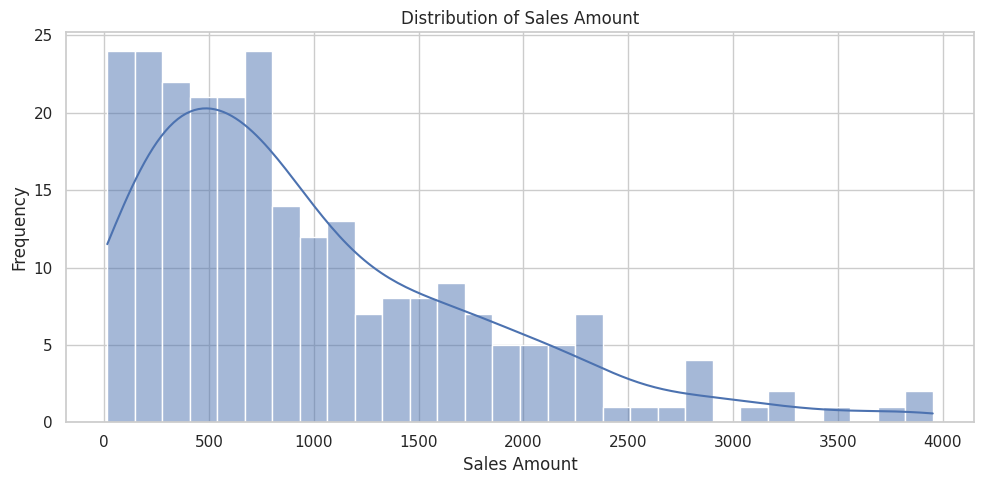

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

plt.figure(figsize=(10, 5))
sns.histplot(df["sales_amount"], bins=30, kde=True)

plt.title("Distribution of Sales Amount")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


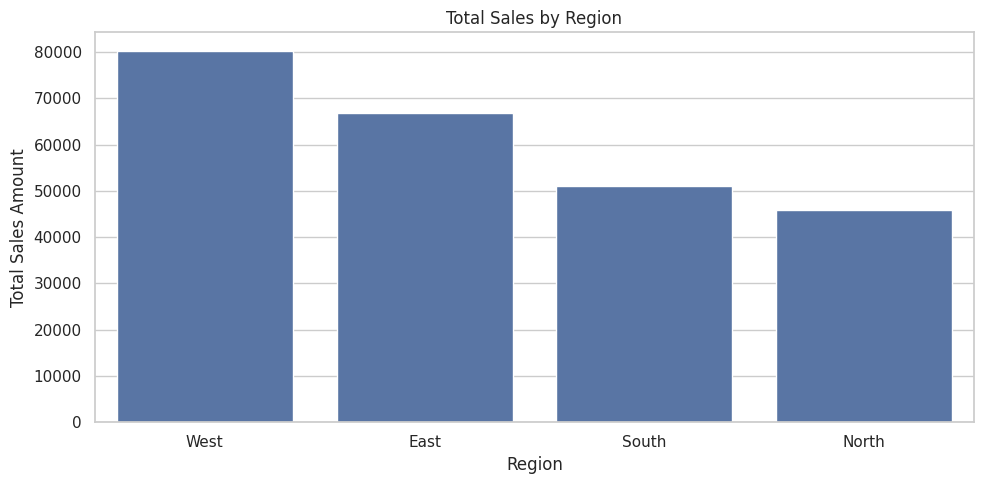

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="region",
    y="sales_amount",
    estimator=sum,
    errorbar=None
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales Amount")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/1145038469.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


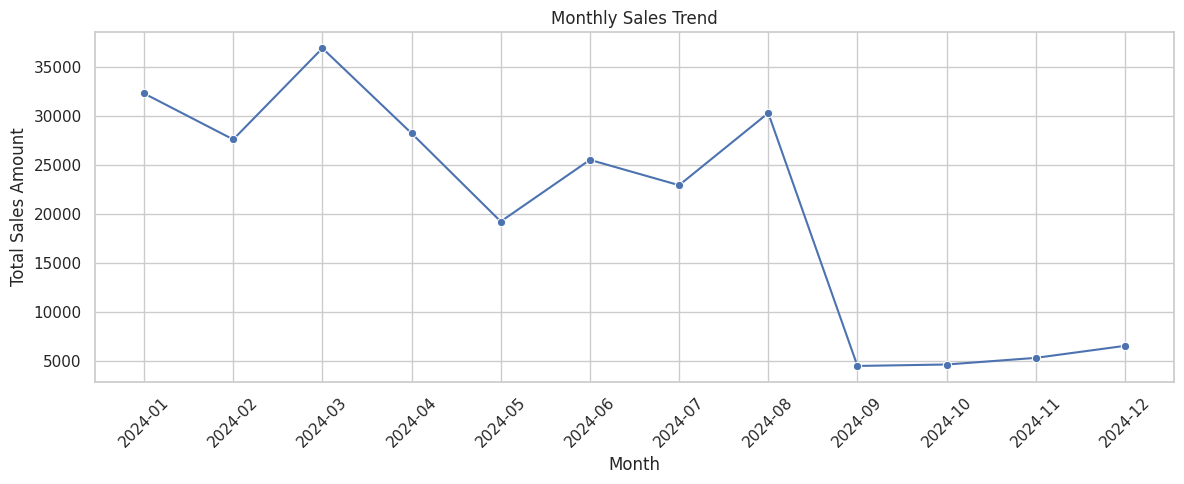

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("month")["sales_amount"].sum().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="sales_amount",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

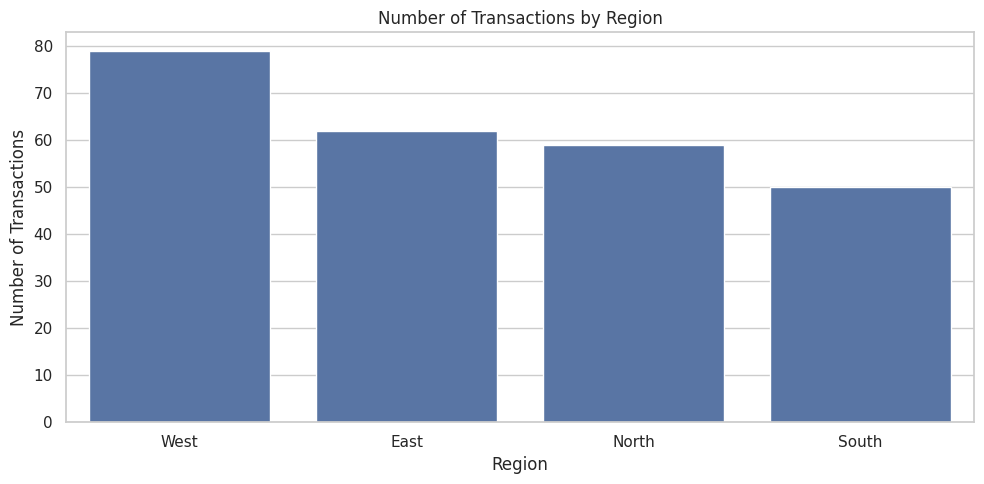

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="region",
    order=df["region"].value_counts().index
)

plt.title("Number of Transactions by Region")
plt.xlabel("Region")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

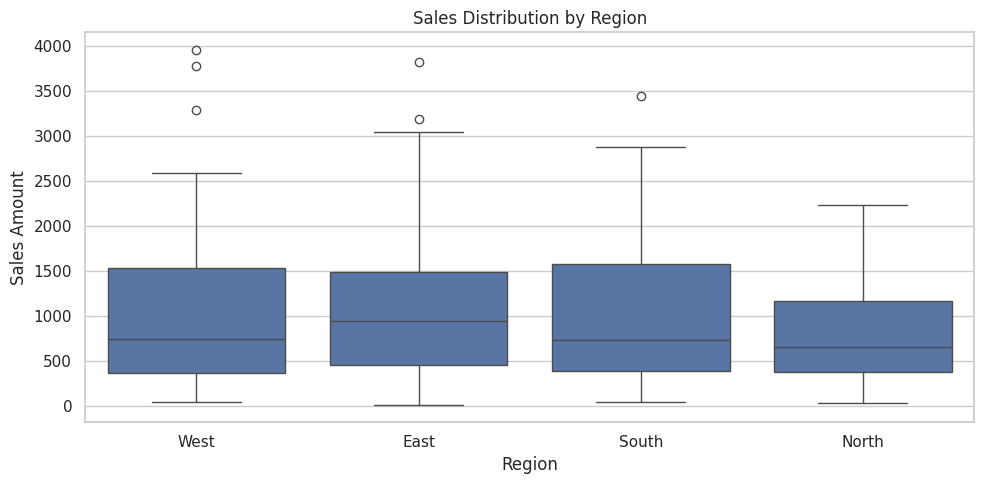

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="region",
    y="sales_amount"
)

plt.title("Sales Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/3239637856.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


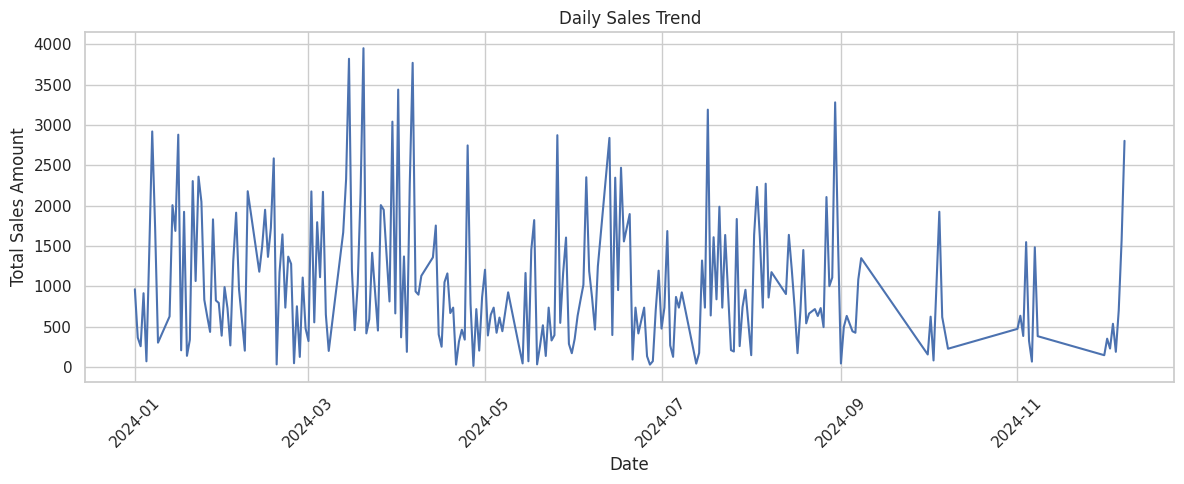

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

daily_sales = df.groupby("date")["sales_amount"].sum().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_sales,
    x="date",
    y="sales_amount"
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales Amount")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

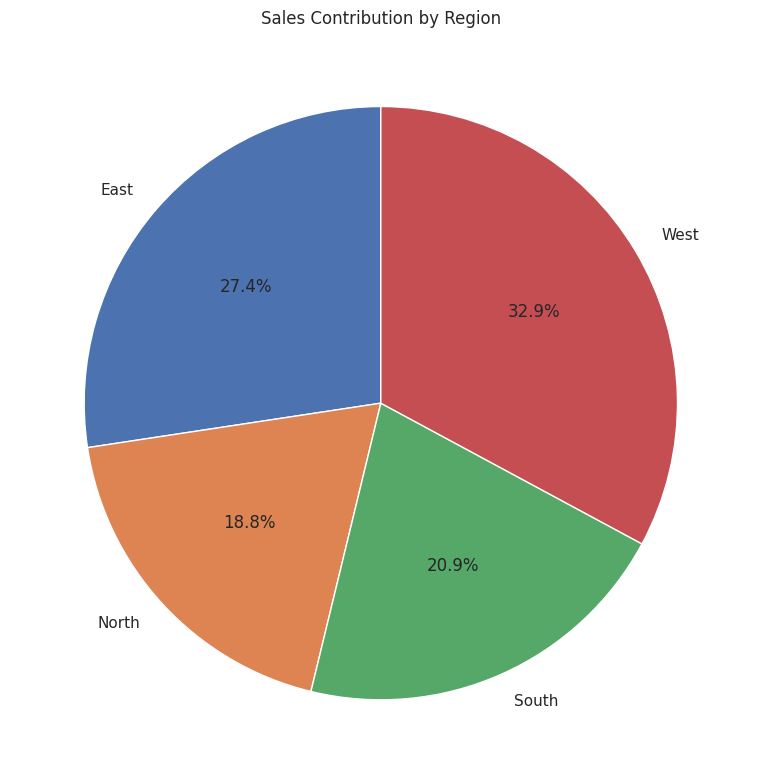

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("final_cleaned_sales_data.csv")

region_sales = df.groupby("region")["sales_amount"].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    region_sales,
    labels=region_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Contribution by Region")

plt.tight_layout()
plt.show()

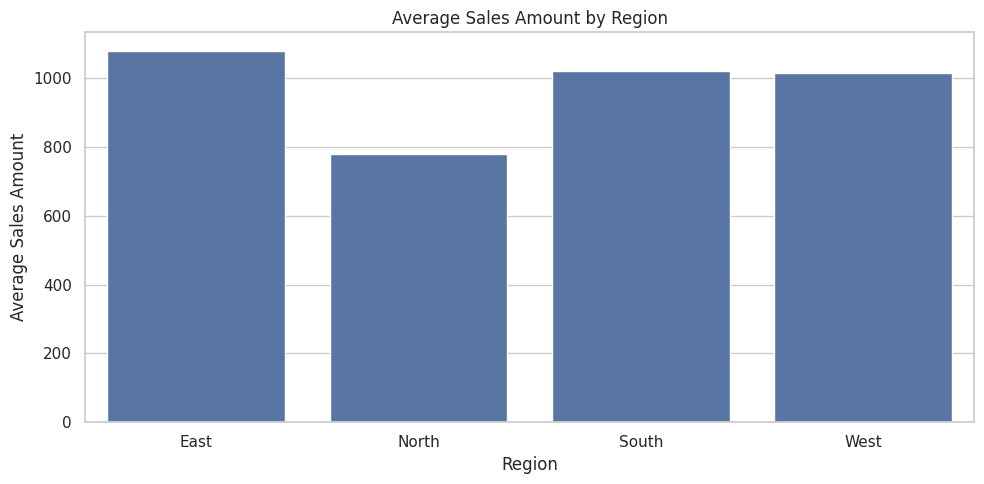

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

average_sales = df.groupby("region")["sales_amount"].mean().reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=average_sales,
    x="region",
    y="sales_amount",
    errorbar=None
)

plt.title("Average Sales Amount by Region")
plt.xlabel("Region")
plt.ylabel("Average Sales Amount")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/940562771.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


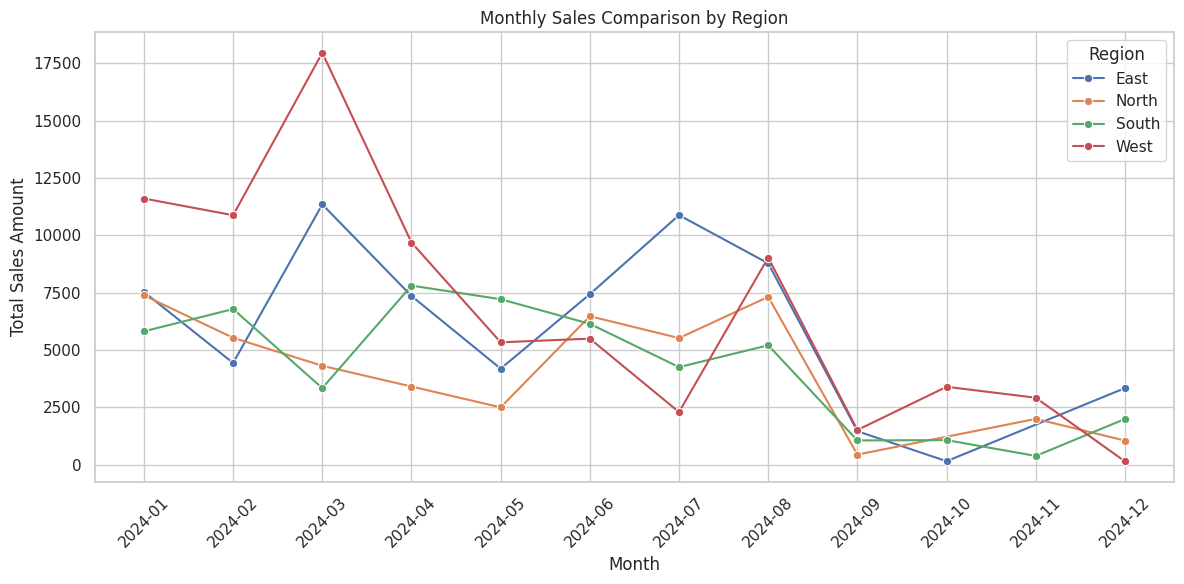

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M").astype(str)

monthly_region_sales = df.groupby(
    ["month", "region"]
)["sales_amount"].sum().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_region_sales,
    x="month",
    y="sales_amount",
    hue="region",
    marker="o"
)

plt.title("Monthly Sales Comparison by Region")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.legend(title="Region")

plt.tight_layout()
plt.show()

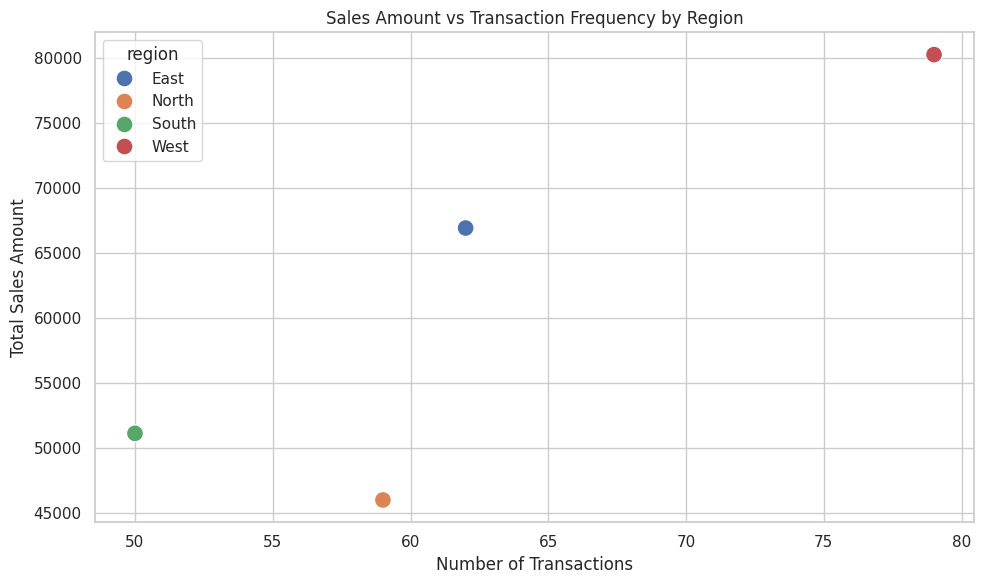

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

region_analysis = df.groupby("region").agg(
    total_sales=("sales_amount", "sum"),
    transaction_count=("transaction_id", "count")
).reset_index()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=region_analysis,
    x="transaction_count",
    y="total_sales",
    hue="region",
    s=150
)

plt.title("Sales Amount vs Transaction Frequency by Region")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Sales Amount")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/3141883474.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


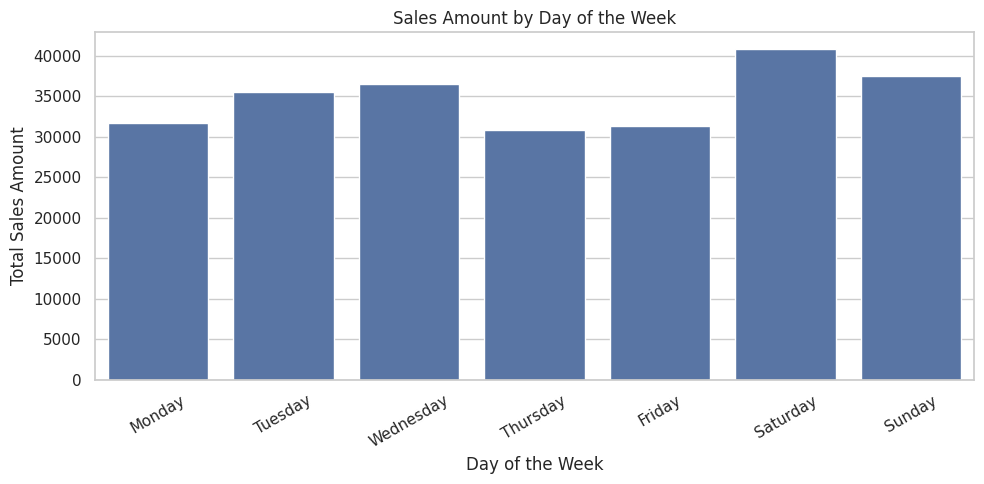

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["day_of_week"] = df["date"].dt.day_name()

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_sales = df.groupby("day_of_week")["sales_amount"].sum().reindex(day_order).reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=daily_sales,
    x="day_of_week",
    y="sales_amount"
)

plt.title("Sales Amount by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

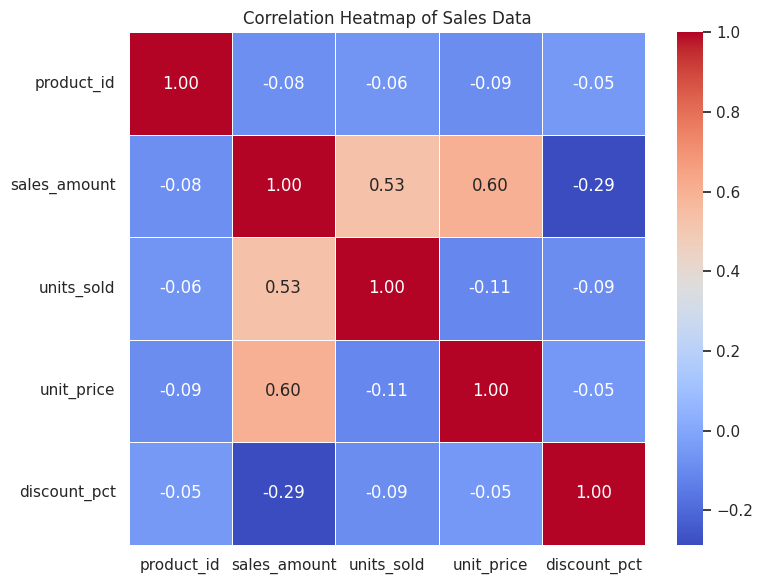

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

numerical_data = df.select_dtypes(include=["number"])

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Sales Data")

plt.tight_layout()
plt.show()

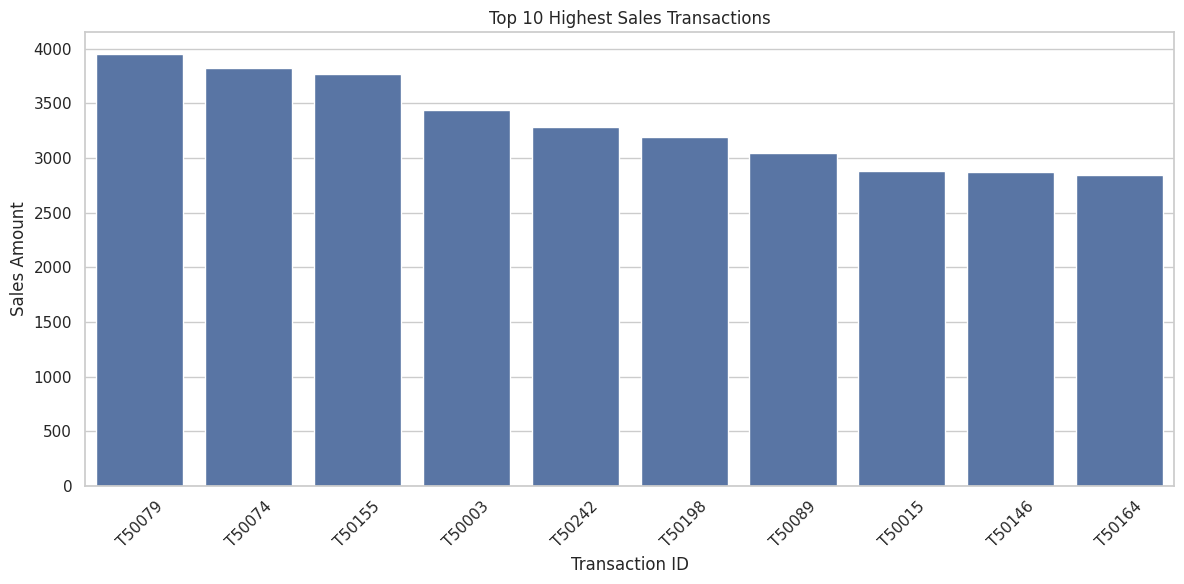

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

top_sales = df.nlargest(10, "sales_amount")

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sales,
    x="transaction_id",
    y="sales_amount"
)

plt.title("Top 10 Highest Sales Transactions")
plt.xlabel("Transaction ID")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

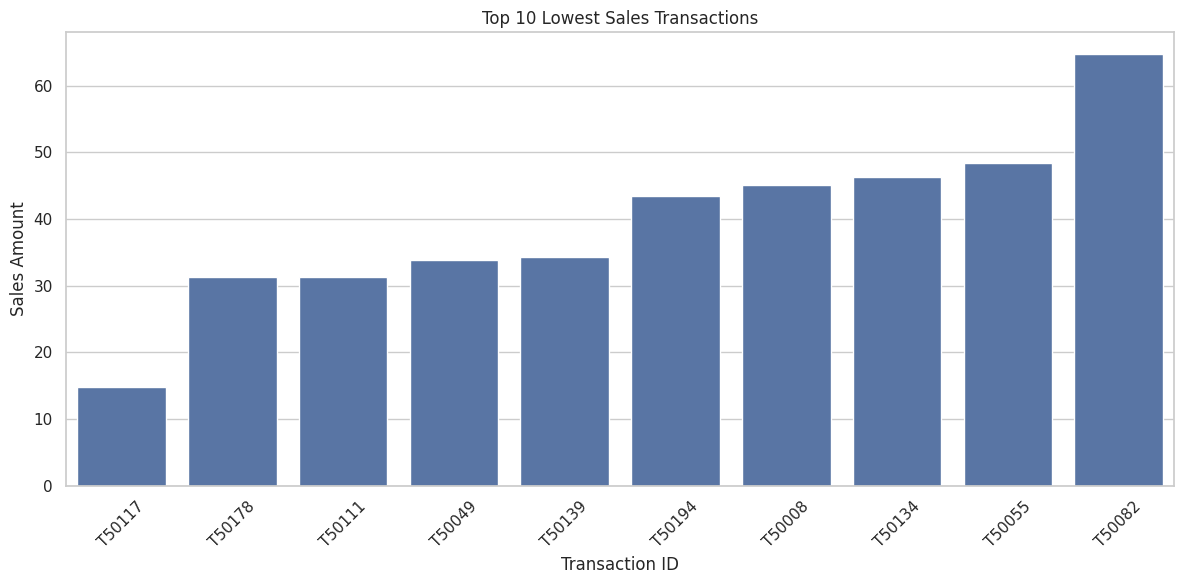

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

lowest_sales = df.nsmallest(10, "sales_amount")

plt.figure(figsize=(12, 6))

sns.barplot(
    data=lowest_sales,
    x="transaction_id",
    y="sales_amount"
)

plt.title("Top 10 Lowest Sales Transactions")
plt.xlabel("Transaction ID")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/1076486598.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


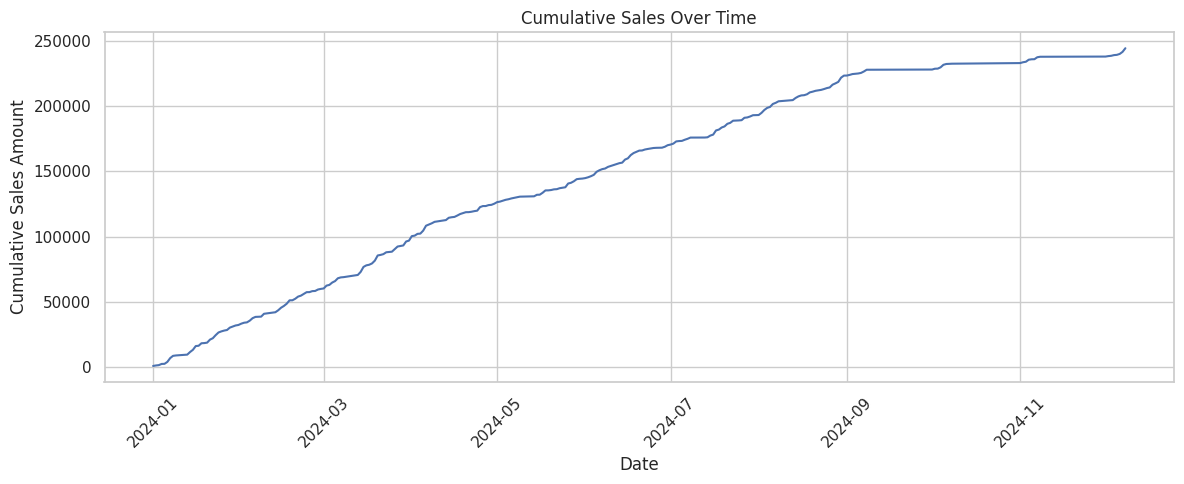

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

daily_sales = df.groupby("date")["sales_amount"].sum().reset_index()

daily_sales = daily_sales.sort_values("date")

daily_sales["cumulative_sales"] = daily_sales["sales_amount"].cumsum()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_sales,
    x="date",
    y="cumulative_sales"
)

plt.title("Cumulative Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Cumulative Sales Amount")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/990555047.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


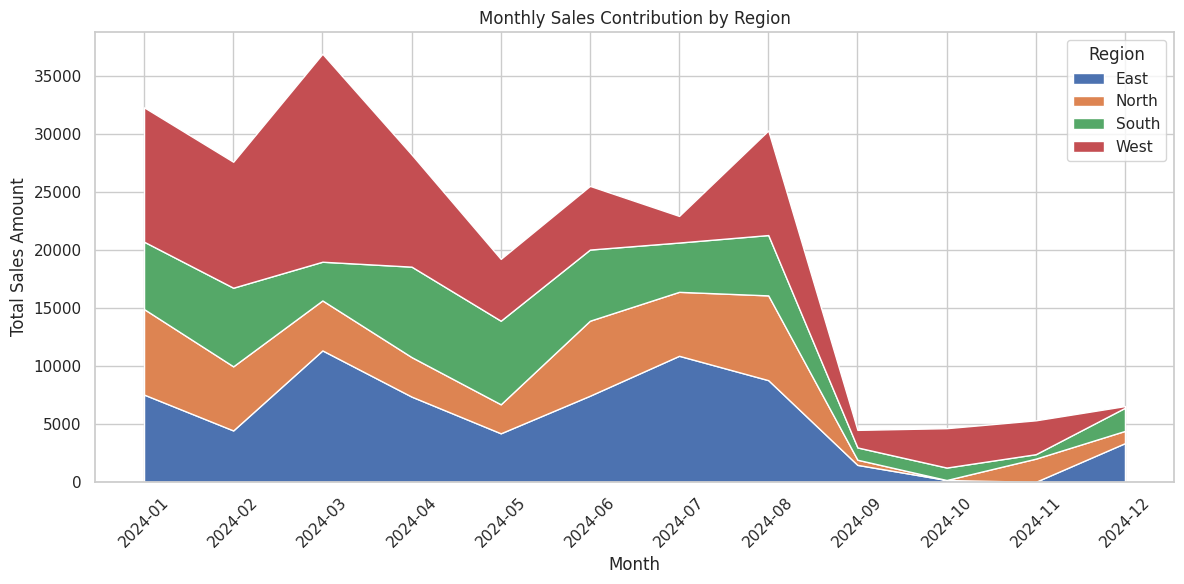

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M")

monthly_region_sales = df.pivot_table(
    index="month",
    columns="region",
    values="sales_amount",
    aggfunc="sum"
).fillna(0)

plt.figure(figsize=(12, 6))

plt.stackplot(
    monthly_region_sales.index.astype(str),
    *[monthly_region_sales[region] for region in monthly_region_sales.columns],
    labels=monthly_region_sales.columns
)

plt.title("Monthly Sales Contribution by Region")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.legend(title="Region")

plt.tight_layout()
plt.show()

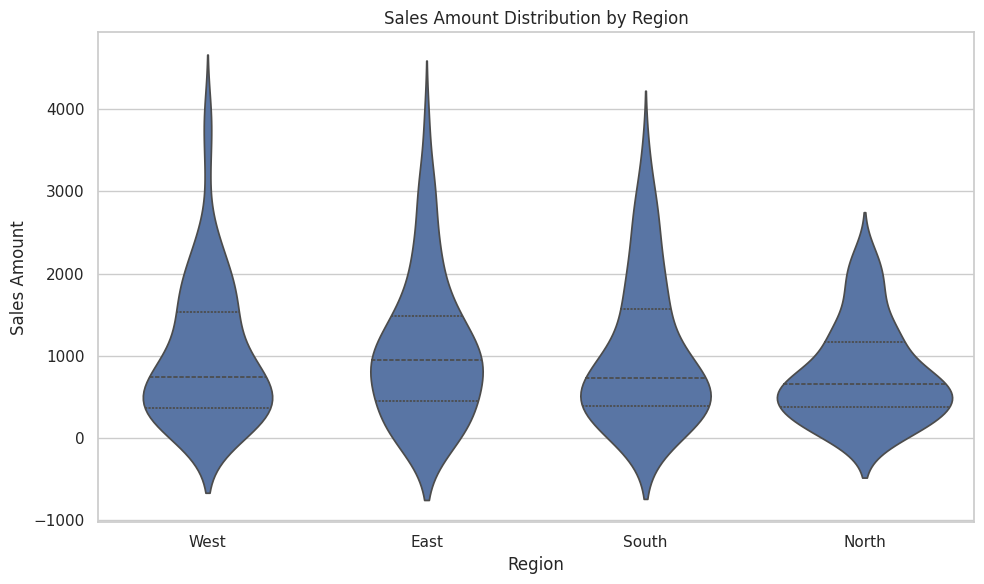

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="region",
    y="sales_amount",
    inner="quartile"
)

plt.title("Sales Amount Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")

plt.tight_layout()
plt.show()


/tmp/ipykernel_1736/412530852.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


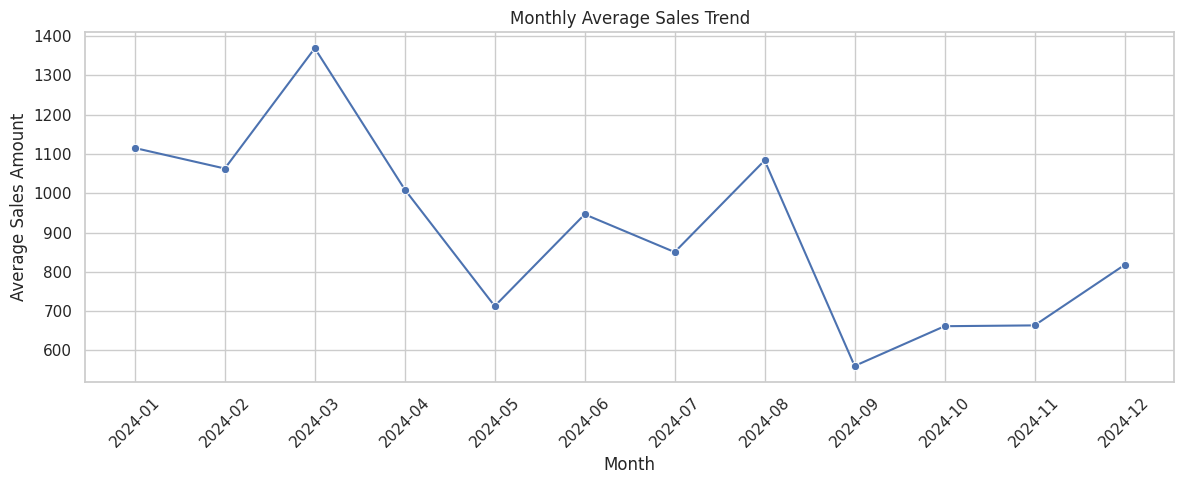

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M").astype(str)

monthly_average = df.groupby("month")["sales_amount"].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_average,
    x="month",
    y="sales_amount",
    marker="o"
)

plt.title("Monthly Average Sales Trend")
plt.xlabel("Month")
plt.ylabel("Average Sales Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/1183323214.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


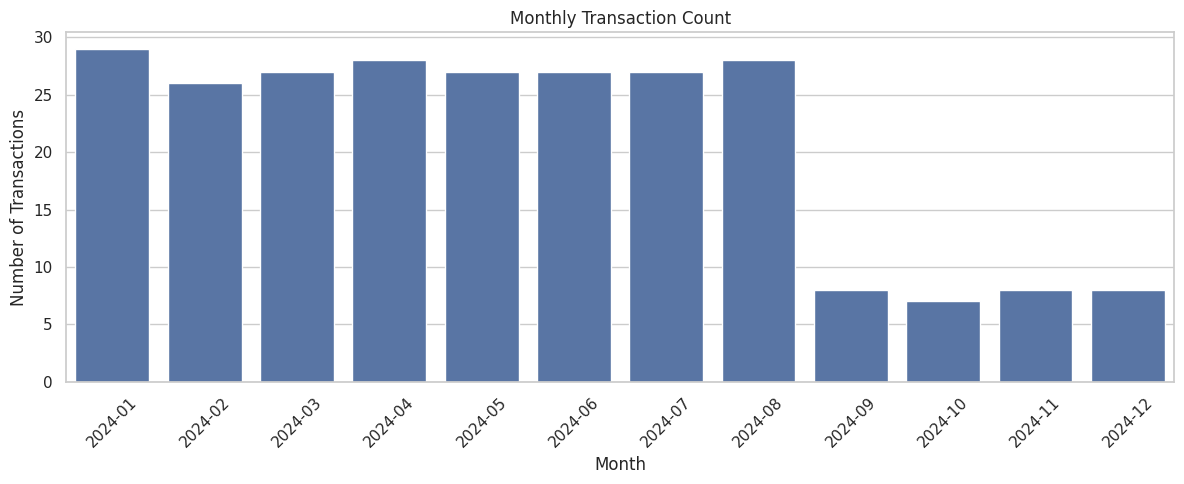

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M").astype(str)

monthly_transactions = df.groupby("month")["transaction_id"].count().reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_transactions,
    x="month",
    y="transaction_id"
)

plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/2555978362.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


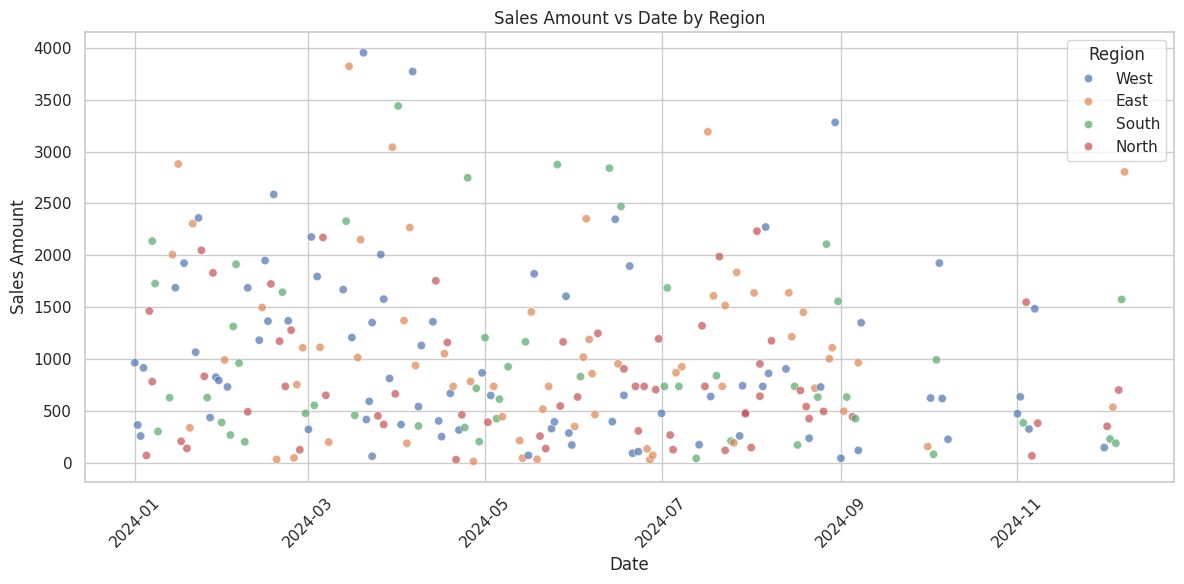

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="date",
    y="sales_amount",
    hue="region",
    alpha=0.7
)

plt.title("Sales Amount vs Date by Region")
plt.xlabel("Date")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.legend(title="Region")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1736/494615918.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


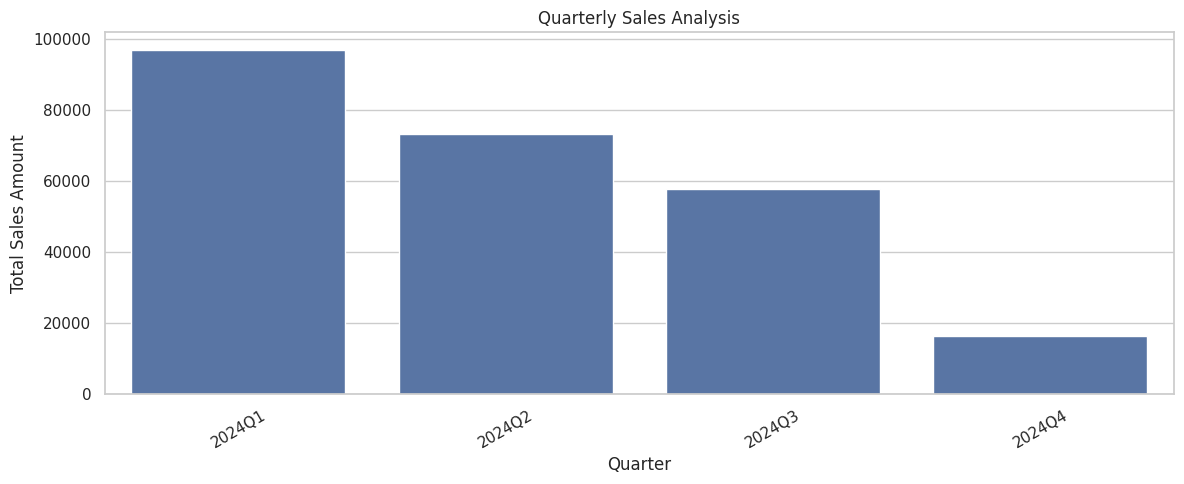

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["quarter"] = df["date"].dt.to_period("Q").astype(str)

quarterly_sales = df.groupby("quarter")["sales_amount"].sum().reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    data=quarterly_sales,
    x="quarter",
    y="sales_amount",
    errorbar=None
)

plt.title("Quarterly Sales Analysis")
plt.xlabel("Quarter")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


/tmp/ipykernel_1736/3295163600.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


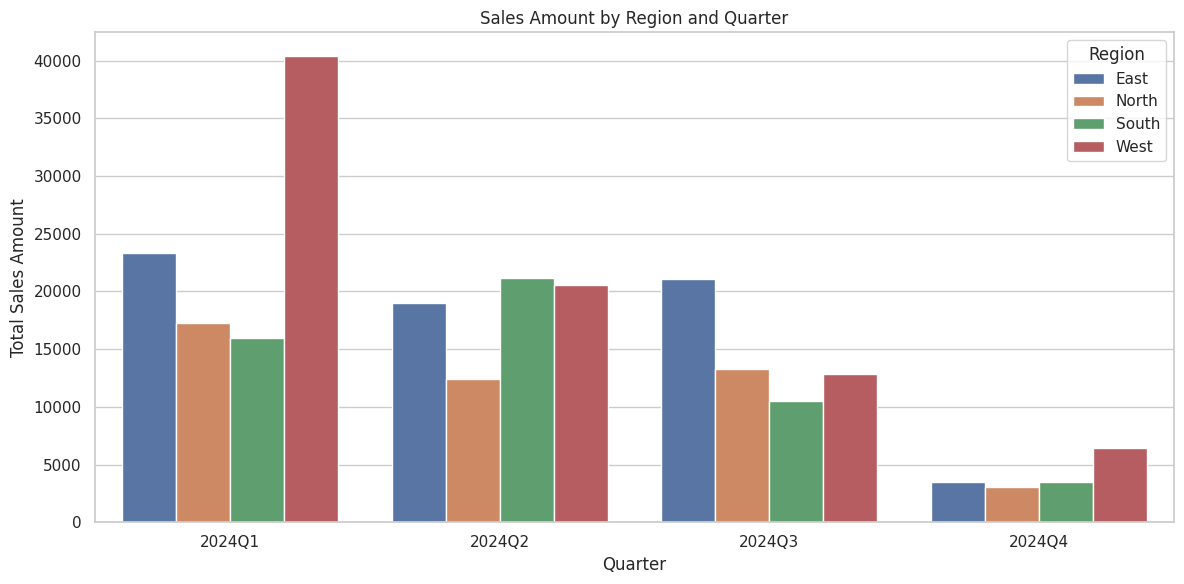

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["quarter"] = df["date"].dt.to_period("Q").astype(str)

quarterly_region_sales = df.groupby(
    ["quarter", "region"]
)["sales_amount"].sum().reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=quarterly_region_sales,
    x="quarter",
    y="sales_amount",
    hue="region",
    errorbar=None
)

plt.title("Sales Amount by Region and Quarter")
plt.xlabel("Quarter")
plt.ylabel("Total Sales Amount")
plt.legend(title="Region")

plt.tight_layout()
plt.show()


/tmp/ipykernel_1736/274608343.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


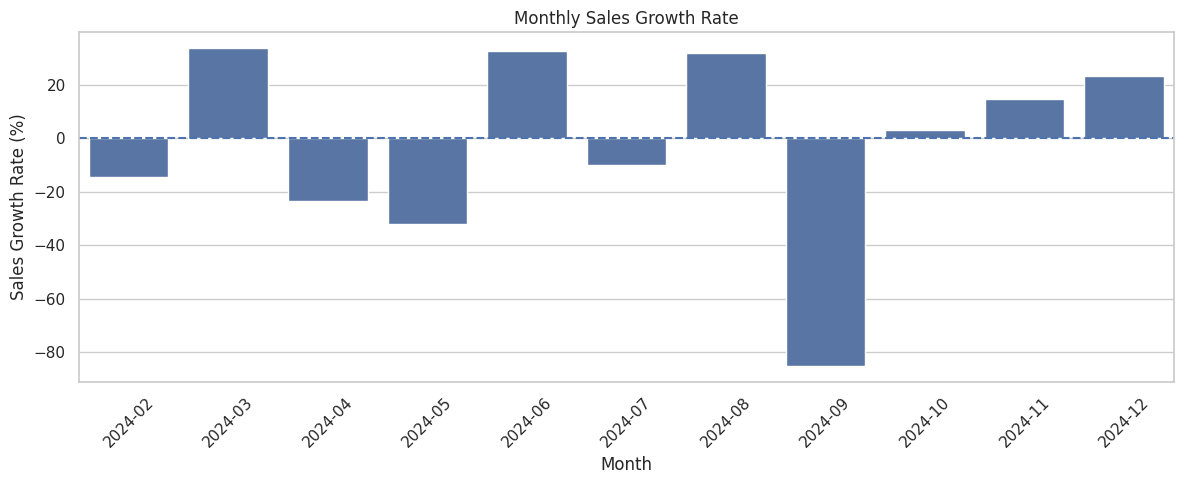

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M")

monthly_sales = df.groupby("month")["sales_amount"].sum().reset_index()

monthly_sales["growth_rate"] = monthly_sales["sales_amount"].pct_change() * 100

monthly_sales["month"] = monthly_sales["month"].astype(str)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_sales.dropna(),
    x="month",
    y="growth_rate"
)

plt.axhline(0, linestyle="--")

plt.title("Monthly Sales Growth Rate")
plt.xlabel("Month")
plt.ylabel("Sales Growth Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

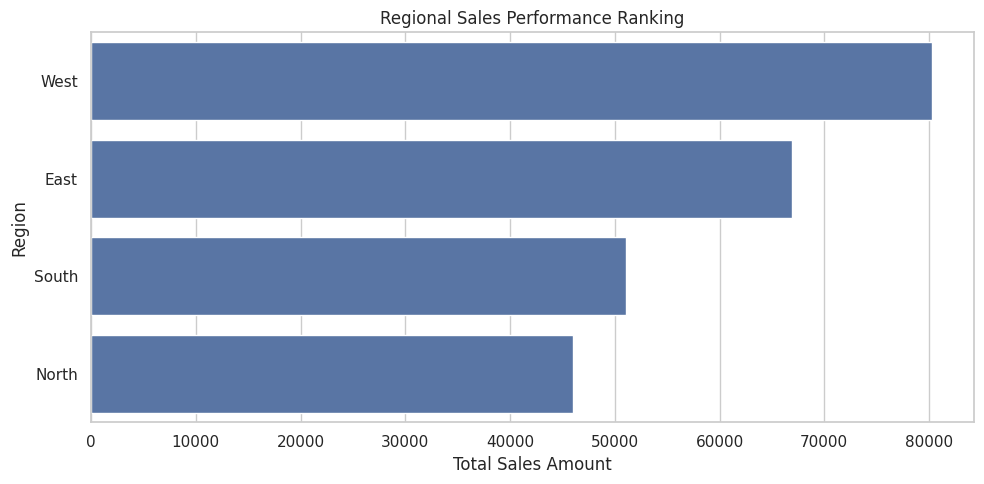

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

region_sales = df.groupby("region")["sales_amount"].sum().reset_index()

region_sales = region_sales.sort_values(
    by="sales_amount",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_sales,
    x="sales_amount",
    y="region"
)

plt.title("Regional Sales Performance Ranking")
plt.xlabel("Total Sales Amount")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

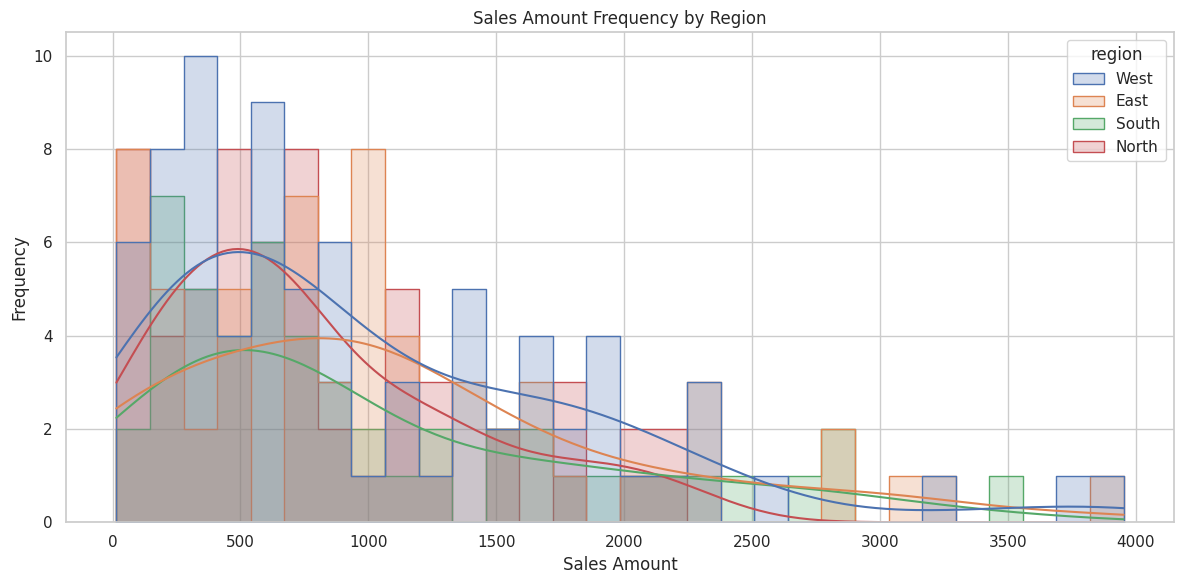

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="sales_amount",
    hue="region",
    bins=30,
    kde=True,
    element="step",
    common_norm=False
)

plt.title("Sales Amount Frequency by Region")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


/tmp/ipykernel_1736/302998653.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


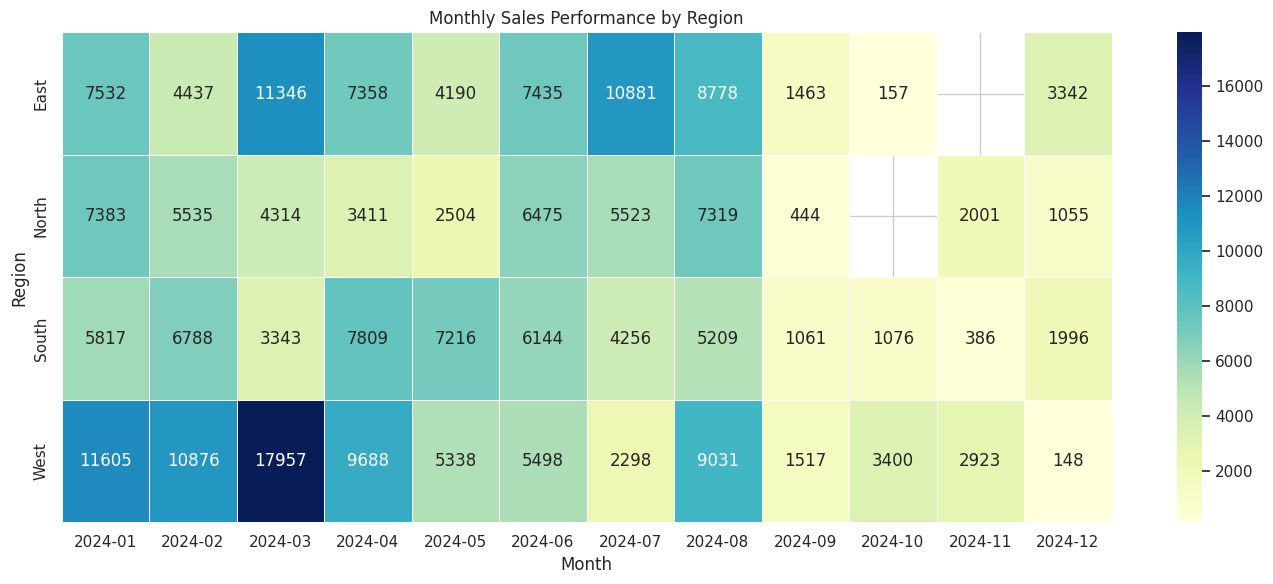

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M").astype(str)

sales_heatmap = df.pivot_table(
    index="region",
    columns="month",
    values="sales_amount",
    aggfunc="sum"
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    sales_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Monthly Sales Performance by Region")
plt.xlabel("Month")
plt.ylabel("Region")

plt.tight_layout()
plt.show()